In [1]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [4]:
print("HELLO")

HELLO


In [6]:
from sklearn.datasets import load_digits
import numpy as np

digits = load_digits()

X = digits.images
y = digits.target

print("Number of images:", len(X))
print("Image shape:", X.shape[1:])
print("Number of classes:", len(np.unique(y)))
print("Classes:", np.unique(y))

Number of images: 1797
Image shape: (8, 8)
Number of classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]


In [7]:
# Normalize pixel values from 0-16 to 0-1
X = X / 16.0

# Add the channel dimension for CNN
X = X.reshape(-1, 8, 8, 1)

print("New image shape:", X.shape)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

New image shape: (1797, 8, 8, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Training images: (1437, 8, 8, 1)
Testing images: (360, 8, 8, 1)


In [9]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential([
    Conv2D(16, (3, 3), activation="relu", padding="same", input_shape=(8, 8, 1)),
    MaxPooling2D((2, 2)),
    
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    
    Flatten(),
    Dense(10, activation="softmax")
])

model.summary()

/opt/anaconda3/envs/week3/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 8, 8, 16)       │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 2, 2, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,090 (23.79 KB)

 Trainable params: 6,090 (23.79 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [12]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2994 - loss: 2.2280 - val_accuracy: 0.4826 - val_loss: 2.1289
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6614 - loss: 1.9392 - val_accuracy: 0.7292 - val_loss: 1.7201
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7981 - loss: 1.3849 - val_accuracy: 0.8264 - val_loss: 1.1003
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8712 - loss: 0.8172 - val_accuracy: 0.8750 - val_loss: 0.6733
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8912 - loss: 0.5230 - val_accuracy: 0.8854 - val_loss: 0.4961
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9156 - loss: 0.3882 - val_accuracy: 0.8993 - val_loss: 0.4042
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9339 - loss: 0.3058 - val_accuracy: 0.9167 - val_loss: 0.3192
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9339 - loss: 0.2582 - val_accuracy: 0.9132 - val_loss:

In [13]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.21365593373775482
Test Accuracy: 0.9194444417953491


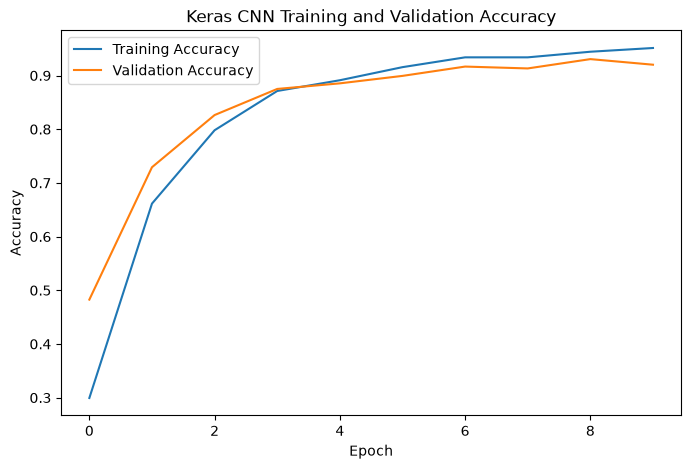

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Keras CNN Training and Validation Accuracy")
plt.legend()
plt.show()

In [16]:
y_pred = model.predict(X_test)

y_pred_classes = np.argmax(y_pred, axis=1)

print("Predictions completed!")
print("First 10 predictions:", y_pred_classes[:10])
print("First 10 actual labels:", y_test[:10])

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Predictions completed!
First 10 predictions: [5 2 8 1 7 2 6 2 6 5]
First 10 actual labels: [5 2 8 1 7 2 6 2 6 5]


In [17]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_classes))

              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.80      0.78      0.79        36
           2       0.88      1.00      0.93        35
           3       1.00      0.95      0.97        37
           4       0.90      1.00      0.95        36
           5       0.97      0.97      0.97        37
           6       1.00      0.92      0.96        36
           7       0.95      0.97      0.96        36
           8       0.82      0.77      0.79        35
           9       0.89      0.86      0.87        36

    accuracy                           0.92       360
   macro avg       0.92      0.92      0.92       360
weighted avg       0.92      0.92      0.92       360



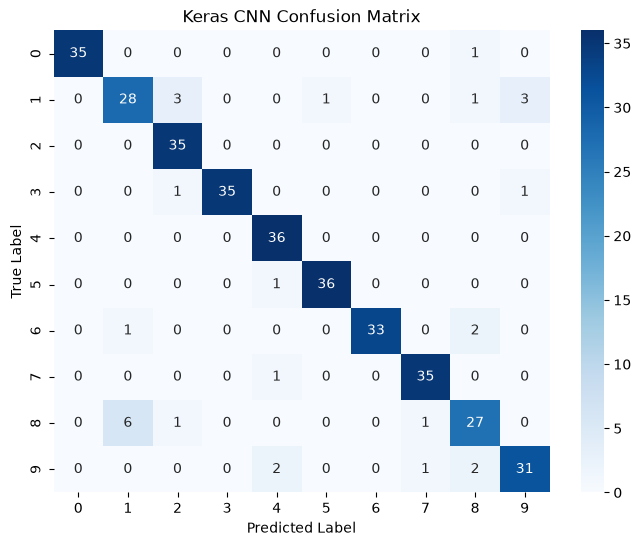

In [18]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Keras CNN Confusion Matrix")
plt.show()

In [19]:
correct = np.sum(y_pred_classes == y_test)
incorrect = np.sum(y_pred_classes != y_test)

print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print("Total test images:", len(y_test))

Correct predictions: 331
Incorrect predictions: 29
Total test images: 360


In [20]:
model.save("keras_digits_cnn.keras")

print("Keras model saved successfully!")

Keras model saved successfully!


In [21]:
pytorch_accuracy = 95.28
keras_accuracy = 91.94

difference = pytorch_accuracy - keras_accuracy

print("PyTorch CNN Accuracy:", pytorch_accuracy, "%")
print("TensorFlow/Keras CNN Accuracy:", keras_accuracy, "%")
print("Difference:", round(difference, 2), "percentage points")

if pytorch_accuracy > keras_accuracy:
    print("PyTorch CNN performed better.")
elif keras_accuracy > pytorch_accuracy:
    print("TensorFlow/Keras CNN performed better.")
else:
    print("Both models had the same accuracy.")

PyTorch CNN Accuracy: 95.28 %
TensorFlow/Keras CNN Accuracy: 91.94 %
Difference: 3.34 percentage points
PyTorch CNN performed better.
